# Integração e Tratamento de Dados

## Preparação do ambiente: 

Ao iniciar um processo de obtenção e tratamento de dados, é sempre importante manter um padrão de trabalho: quais bibliotecas são carregadas, quais funções são tornadas disponíveis, ajuste dos parâmetros para resultados dentro da norma da empresa etc.

In [42]:
# eliminar todas variáveis ativas no ambiente
# ls() → lista variáveis definidas
# rm(variáveis) → remove variáveis da memória
rm(list=ls()) # → remove a lista contendo todas as variáveis

In [207]:
# biblioteca de definição de representações
library(repr)

# função para definir dimensão da célula de gráfico no Jupyter:
dimgraf <- function (x=11, y=7) { 
    options(repr.plot.width=x,repr.plot.height=y) 
}

## Extração

### Obtenção dos dados

Os dados frequentemente são disponibilizados nos mais diferentes formatos e fontes. É importante importá-los do modo mais direto possível, evitando múltiplos passos no processo pois cada passo incorre em complexidade e possibilidade de alteração nos valores dos dados.

R possibilita a leitura dos dados de diversas fontes, como planilhas eletrônicas, consultas SQL, teclado etc.

O comando `read.table` é o comando genérico para leitura de dados na forma de tabela de dados. 

In [29]:
txtdados <- 
"idade sexo peso 
  25 m 78 
  30 f 65 
  18 f 63"

In [30]:
dados <- read.table(header=TRUE, text=txtdados)
dados

idade,sexo,peso
<int>,<chr>,<int>
25,m,78
30,f,65
18,f,63


A forma mais comum, por ser bastante neutra é o formato CSV (_comma separated values_, valores separados por vírgula). A maior parte dos conjuntos de dados (_datasets_) são disponibilizados em CSV. Há alguns inconvenientes, porém. Algumas linguas utilizam a vírgula para separar casas decimais e os separadores no arquivo são outros; texto pode ou não estar guardado por aspas etc.

Exemplo do início do arquivo de dados `cepagri_2017_2022.csv`:

```raw
01/01/2017-00:00;22.2;16.2;83.9;21.1
01/01/2017-00:10; [ERRO]
01/01/2017-00:20; [ERRO]
01/01/2017-00:30; [ERRO]
01/01/2017-00:40; [ERRO]
01/01/2017-00:50; [ERRO]
01/01/2017-01:00; [ERRO]
01/01/2017-01:10; [ERRO]
01/01/2017-01:20;21.7;4.0;84.7;20.6
01/01/2017-01:30;21.5;9.2;87.6;20.3
01/01/2017-01:40;21.6;7.8;86.4;20.4
01/01/2017-01:50;21.2;11.6;87.7;20.1
01/01/2017-02:00;21.3;0.5;87.4;20.2
01/01/2017-02:10;21.5;4.0;85.3;20.3
...
```

É possível observar que os valores numéricos, apesar de usarem ponto como separador decimal, fazem a separação dos valores por ponto e vírgula `;`. Isso sem mencionar os erros `[ERRO]`...

Há um comando pré-configurado para a leitura de texto no formato CSV: `read.csv(arquivo, parâmetros)`. Por exemplo:

```R
dados <- read.csv("arquivo.csv", header=TRUE, sep=",") 
```

- ler os dados de `arquivo.csv`; 
- o nome das variáveis está na primeira linha: `header=TRUE`. Se for `FALSE`, R vai atribuir nomes `V1`, `V2`... às variáveis. Se for omitido, R vai utilizar os valores da primeira linha como nome das variáveis;
- o separador entre os valores é a `,`: (`sep=","`);
- algumas versões do R ___muito___ antigas convertem texto pra fator sendo necessário o parâmetro `stringsAsFactors = FALSE` na leitura do `read.csv`.

É possível ler já descompactando de um arquivo compactado (zip, gz etc) informando qual é o arquivo dentro do arquivo .zip. 

In [2]:
# ler dados de um arquivo compactado, com valores separados por ";", 
# sem nome das variáveis na primeira linha
cepagri_00 <- read.csv(unzip("cepagri_2017_2022.zip","cepagri_2017_2022.csv"),
                       sep=";", header=FALSE)

Vamos então importar os dados do arquivo `cepagri_2017_2022.csv`, que contém dados da estação meteorológica "Centro de Pesquisas Meteorológicas e Climáticas Aplicadas à Agricultura" da Unicamp:

In [4]:
cepagri_00 <- read.csv("cepagri_2017_2022.csv", header=FALSE, sep=";")
cepagri_00

V1,V2,V3,V4,V5
<chr>,<chr>,<dbl>,<dbl>,<dbl>
01/01/2017-00:00,22.2,16.2,83.9,21.1
01/01/2017-00:10,[ERRO],NA,NA,NA
01/01/2017-00:20,[ERRO],NA,NA,NA
01/01/2017-00:30,[ERRO],NA,NA,NA
01/01/2017-00:40,[ERRO],NA,NA,NA
01/01/2017-00:50,[ERRO],NA,NA,NA
01/01/2017-01:00,[ERRO],NA,NA,NA
01/01/2017-01:10,[ERRO],NA,NA,NA
01/01/2017-01:20,21.7,4.0,84.7,20.6


In [8]:
head(cepagri_00,10)  # os primeiros 10 valores
tail(cepagri_00,10)  # os últimos 10 valores

,V1,V2,V3,V4,V5
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,01/01/2017-00:00,22.2,16.2,83.9,21.1
2,01/01/2017-00:10,[ERRO],NA,NA,NA
3,01/01/2017-00:20,[ERRO],NA,NA,NA
4,01/01/2017-00:30,[ERRO],NA,NA,NA
5,01/01/2017-00:40,[ERRO],NA,NA,NA
6,01/01/2017-00:50,[ERRO],NA,NA,NA


,V1,V2,V3,V4,V5
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
282369,07/06/2022-08:40,18.3,6.7,74.5,16.9
282370,07/06/2022-08:50,18.7,6.5,74.3,17.3
282371,07/06/2022-09:00,19.3,5.5,73.2,17.9
282372,07/06/2022-09:10,19.2,5.6,73.1,17.8
282373,07/06/2022-09:20,19.6,5.2,73.2,18.3
282374,07/06/2022-09:30,19.4,4.5,74.1,18.1


Os dados estão disponíveis dentro do _data frame_ `cepagri_00`. É possível agora examinar o que o R entendeu dos valores lidos:

In [6]:
summary(cepagri_00)

      V1                 V2                  V3               V4        
 Length:282374      Length:282374      Min.   :  0.00   Min.   :  0.00  
 Class :character   Class :character   1st Qu.: 10.70   1st Qu.: 55.10  
 Mode  :character   Mode  :character   Median : 19.30   Median : 71.10  
                                       Mean   : 23.01   Mean   : 67.29  
                                       3rd Qu.: 32.20   3rd Qu.: 81.60  
                                       Max.   :120.10   Max.   :100.00  
                                       NA's   :34366    NA's   :34366   
       V5       
 Min.   :-0.20  
 1st Qu.:17.50  
 Median :20.50  
 Mean   :20.84  
 3rd Qu.:24.60  
 Max.   :99.90  
 NA's   :34366  

Podemos também pedir para ver a estrutura do _data frame_ `cepagri_00`:

In [79]:
str(cepagri_00)

'data.frame':	282374 obs. of  5 variables:
 $ V1: chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ V2: chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ V3: num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ V4: num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ V5: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


As variáveis `V1` a `V5` são, respectivamento o **marco temporal** (_timestamp_) em que ocorreu a medida (variável `horario`), a **temperatura** medida em °C (`temp`), a **velocidade do vento** em km/h (`vento`), a **umidade** do ar em % (`umid`) e a **sensação térmica** em °C (`sensacao`).  
Vamos então atribuir esses nomes às variáveis com nomes genéricos de `cepagri_00`:

In [64]:
names(cepagri_00) <- c("horario","temp","vento","umid","sensacao")

Estrutura do _data frame_ `cepagri_00` que contém os dados:

In [50]:
str(cepagri_00)

'data.frame':	282374 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ temp    : chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ vento   : num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ umid    : num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ sensacao: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


O processo de captura, transformação e carga dos dados costuma ser complexo, com diversas necessidades de alteração de algum passo, criação/exclusão de alguma(s) variável(is). Uma técnica para tornar tal processo administrável é compartimentalizá-lo em passos ou etapas. Cada etapa é estruturada de modo a indicar um _passo do processo_ realizado e, em geral, fica a critério do profissional. Aqui separamos o primeiro passo com a leitura do arquivo, nomeação inicial das variáveis e observação superficial dos seus valores. Os dados então são salvos para que, caso haja a necessidade futura, serem retomados _deste ponto_.

In [53]:
# arquivo original em formato R: compacto e eficiente para carregar
save(cepagri_00, file="cepagri_00_captura.RData")

## Transformação

O próximo passo é a avaliação da estrutura das variáveis e sua adequação para os procedimentos de análise.

In [206]:
rm(list=ls()) # Limpando variáveis intermediárias da memória
load("cepagri_00_captura.RData")
ls()

[1] "cepagri_00"

In [208]:
# é comum utilizar o nome df (data frame) para trabalhar (mais curto que cepagri_00).
df <- cepagri_00
# liberando o cepagri_00 da memória
rm(cepagri_00)

### Horário

Falta apenas fazer com que o horário seja registrado no _data frame_ como um marco temporal, com data e horário. Isso é feito com a conversão das funções `POSIXcd` (ecoômica para armazenagem) e `POSIXlt` (fácil para consultar). 

In [209]:
str(df)

'data.frame':	282374 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ temp    : chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ vento   : num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ umid    : num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ sensacao: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


In [210]:
df$horario <- as.POSIXct(df$horario, format='%d/%m/%Y-%H:%M', 
                         tz="America/Sao_Paulo")

In [211]:
summary(df)

    horario                           temp               vento       
 Min.   :2017-01-01 00:00:00.00   Length:282374      Min.   :  0.00  
 1st Qu.:2018-05-10 18:32:30.00   Class :character   1st Qu.: 10.70  
 Median :2019-09-15 17:05:00.00   Mode  :character   Median : 19.30  
 Mean   :2019-09-18 05:59:36.57                      Mean   : 23.01  
 3rd Qu.:2021-01-27 14:57:30.00                      3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00.00                      Max.   :120.10  
                                                     NA's   :34366   
      umid           sensacao    
 Min.   :  0.00   Min.   :-0.20  
 1st Qu.: 55.10   1st Qu.:17.50  
 Median : 71.10   Median :20.50  
 Mean   : 67.29   Mean   :20.84  
 3rd Qu.: 81.60   3rd Qu.:24.60  
 Max.   :100.00   Max.   :99.90  
 NA's   :34366    NA's   :34366  

É interessante para a análise os anos e meses em que as medidas ocorreram e, para facilitar o acesso, estes valores serão transformados em variáveis.

### Temperatura

In [212]:
# Por quê a temperatura foi importada como texto? 
# achar os registros de temperatura que têm caracteres:
linhas <- grep("[A-Za-z]", df$temp)
length(linhas)
head(linhas,10)
tail(linhas,10)

[1] 34366

[1]    2    3    4    5    6    7    8 1830 1831 1832

[1] 281928 282030 282071 282072 282215 282216 282264 282318 282359 282360

In [213]:
head(df[linhas,],10)

,horario,temp,vento,umid,sensacao
,<dttm>,<chr>,<dbl>,<dbl>,<dbl>
2,2017-01-01 00:10:00,[ERRO],NA,NA,NA
3,2017-01-01 00:20:00,[ERRO],NA,NA,NA
4,2017-01-01 00:30:00,[ERRO],NA,NA,NA
5,2017-01-01 00:40:00,[ERRO],NA,NA,NA
6,2017-01-01 00:50:00,[ERRO],NA,NA,NA
7,2017-01-01 01:00:00,[ERRO],NA,NA,NA
8,2017-01-01 01:10:00,[ERRO],NA,NA,NA
1830,2017-01-14 23:10:00,[ERRO],NA,NA,NA
1831,2017-01-14 23:20:00,[ERRO],NA,NA,NA


Ops, tem valores de temperatura registradas como "[ERRO]", causaram a perda dos valores das demais variáveis e não permitiram que `temp` fosse interpretada como um número.

In [214]:
# Excluindo as linhas com "[ERRO]" na temperatura de df
df <- df[-linhas,]

In [215]:
str(df)

'data.frame':	248008 obs. of  5 variables:
 $ horario : POSIXct, format: "2017-01-01 00:00:00" "2017-01-01 01:20:00" ...
 $ temp    : chr  "22.2" "21.7" "21.5" "21.6" ...
 $ vento   : num  16.2 4 9.2 7.8 11.6 0.5 4 5.4 0 0 ...
 $ umid    : num  83.9 84.7 87.6 86.4 87.7 87.4 85.3 83.6 82.2 82.3 ...
 $ sensacao: num  21.1 20.6 20.3 20.4 20.1 20.2 20.3 20.6 20.9 20.9 ...


Dispensadas 34366 linhas com problemas. Ainda há texto em `temp`?

In [216]:
linhas <- grep("[A-Za-z]", df$temp)
linhas
length(linhas)

integer(0)

[1] 0

Não há mais texto, então pode ser convertida para número:

In [217]:
df$temp <- as.numeric(df$temp)

Como está a estrutura do `data frame`

In [218]:
str(df)

'data.frame':	248008 obs. of  5 variables:
 $ horario : POSIXct, format: "2017-01-01 00:00:00" "2017-01-01 01:20:00" ...
 $ temp    : num  22.2 21.7 21.5 21.6 21.2 21.3 21.5 21.7 22 22 ...
 $ vento   : num  16.2 4 9.2 7.8 11.6 0.5 4 5.4 0 0 ...
 $ umid    : num  83.9 84.7 87.6 86.4 87.7 87.4 85.3 83.6 82.2 82.3 ...
 $ sensacao: num  21.1 20.6 20.3 20.4 20.1 20.2 20.3 20.6 20.9 20.9 ...


Aparentemente, ok.   
Mas será?

In [219]:
summary(df)

    horario                            temp           vento       
 Min.   :2017-01-01 00:00:00.00   Min.   : 4.60   Min.   :  0.00  
 1st Qu.:2018-03-20 21:27:30.00   1st Qu.:18.90   1st Qu.: 10.70  
 Median :2019-05-29 00:45:00.00   Median :21.70   Median : 19.30  
 Mean   :2019-07-21 01:54:23.86   Mean   :22.22   Mean   : 23.01  
 3rd Qu.:2020-12-28 11:32:30.00   3rd Qu.:25.80   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00.00   Max.   :37.40   Max.   :120.10  
      umid           sensacao    
 Min.   :  0.00   Min.   :-0.20  
 1st Qu.: 55.10   1st Qu.:17.50  
 Median : 71.10   Median :20.50  
 Mean   : 67.29   Mean   :20.84  
 3rd Qu.: 81.60   3rd Qu.:24.60  
 Max.   :100.00   Max.   :99.90  

Entre 4,6°C e 37,4°C, com média em 22,2°C. Parece Campinas...

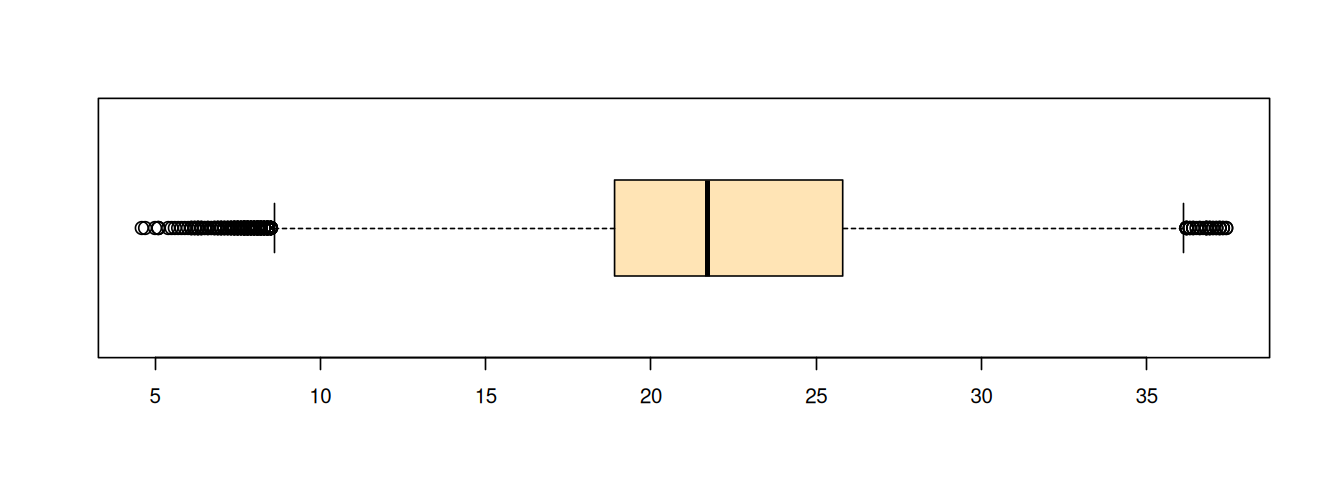

In [220]:
dimgraf(11,4)
boxplot(df$temp, horizontal=TRUE, cex=1.3, col="moccasin")

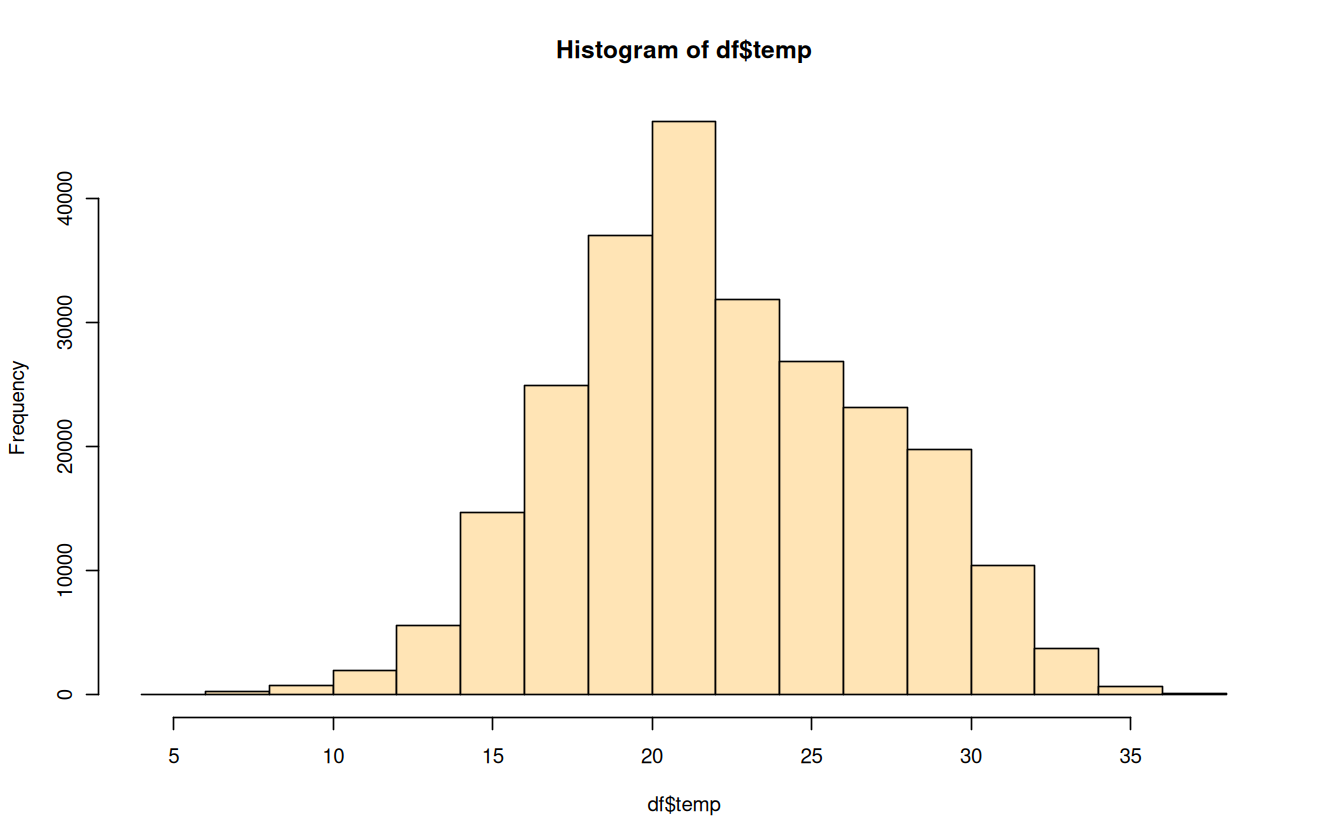

In [221]:
dimgraf(11,7)
hist(df$temp, col="moccasin")

Como é o comportamento das temperaturas abaixo de 10 °C?

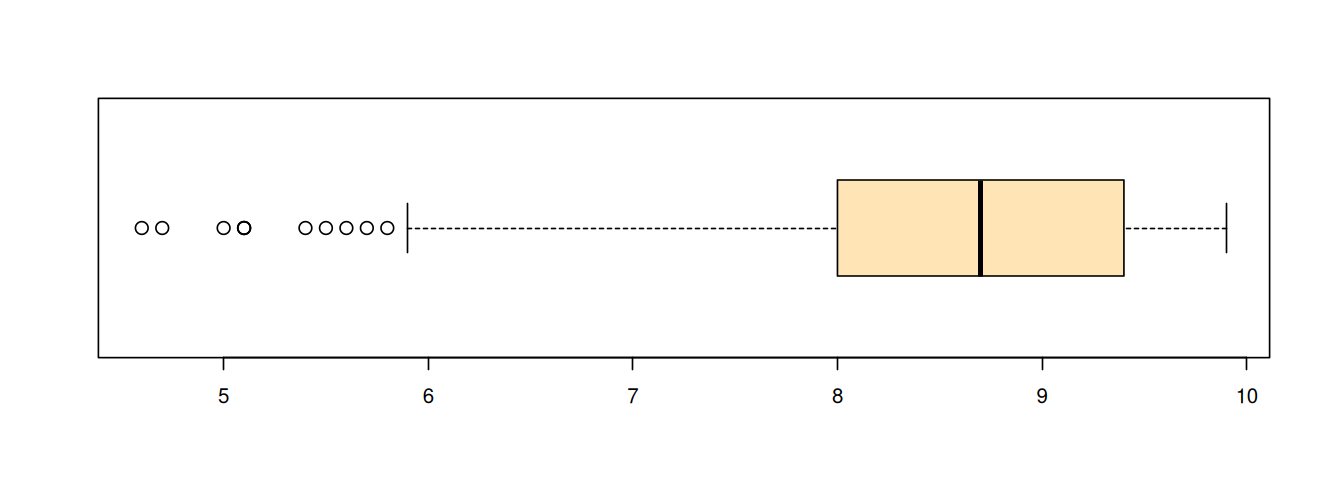

In [222]:
dimgraf(11,4)
boxplot(df$temp[df$temp < 10], horizontal=TRUE, cex=1.3, col="moccasin")

In [223]:
df$temp[df$temp < 6]

[1] 5.8 5.7 5.9 5.4 5.1 4.6 4.7 5.0 5.1 5.1 5.5 5.6

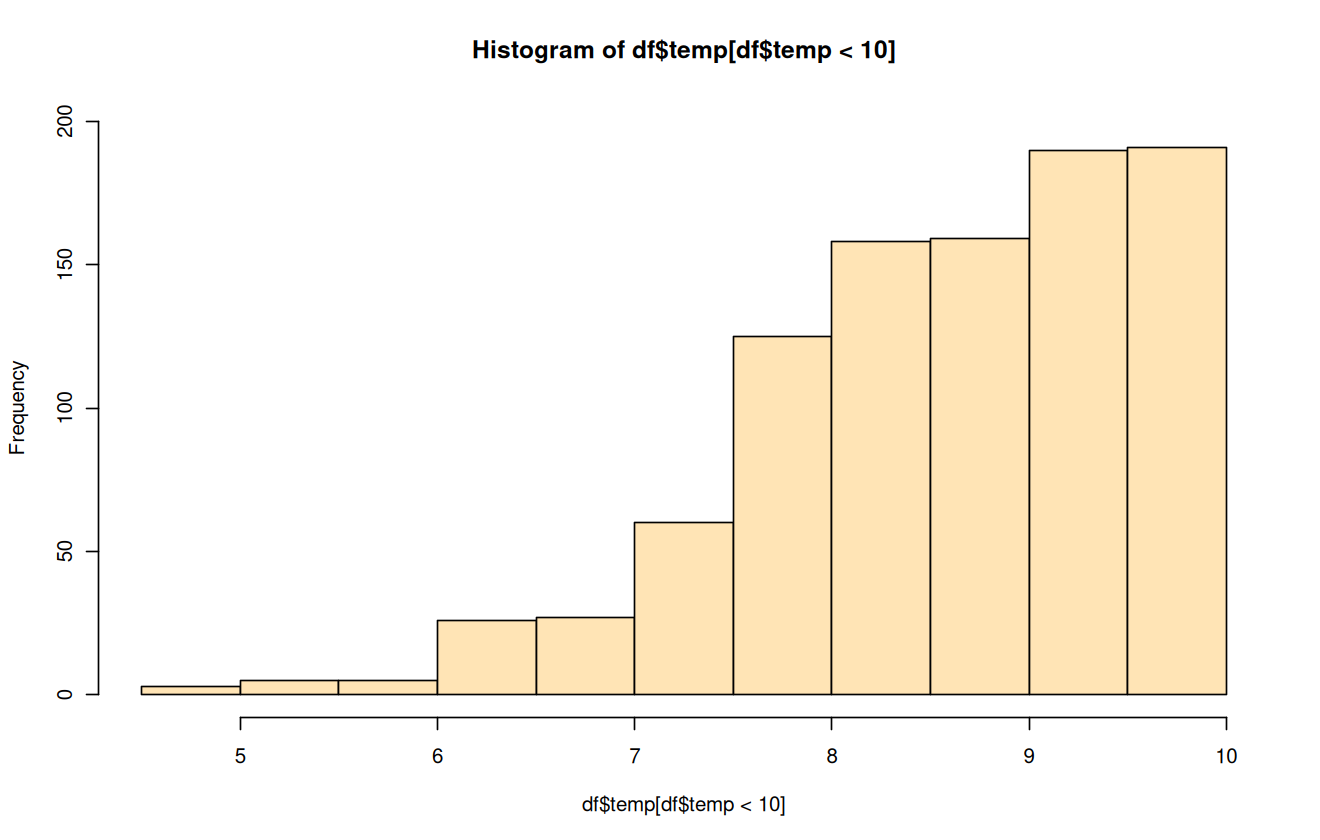

In [224]:
dimgraf(11,7)
hist(df$temp[df$temp<10], col="moccasin", ylim=c(0,200))

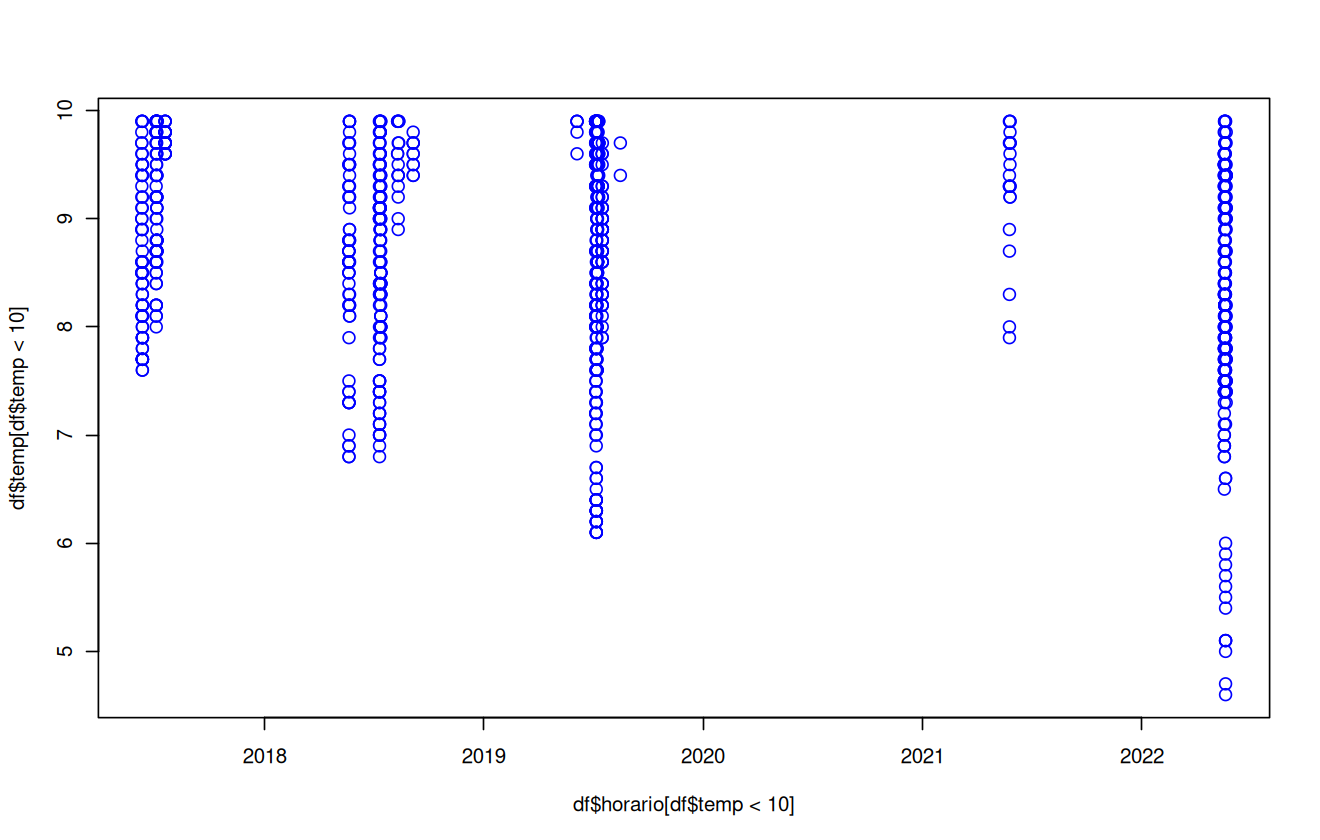

In [225]:
dimgraf(11,7)
plot(df$horario[df$temp<10],df$temp[df$temp<10], col="blue", cex=1.2)

Parece inverno pra mim...

### Velocidade do vento

Mínimo em 0 km/h e máximo em 120 km/h. **Ops**.

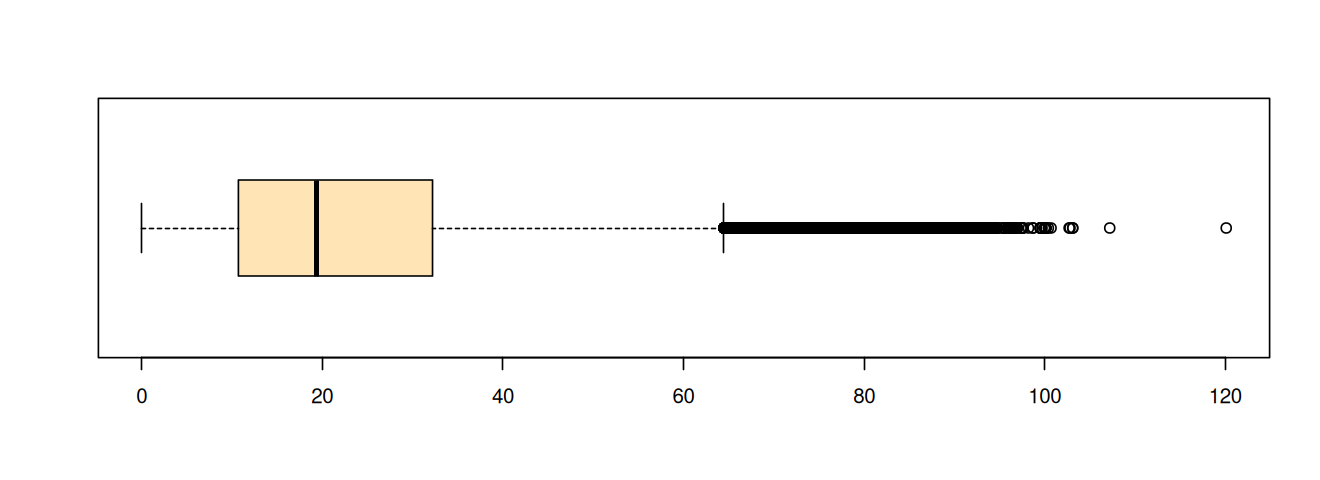

In [226]:
dimgraf(11,4)
boxplot(df$vento, horizontal=TRUE, col="moccasin")

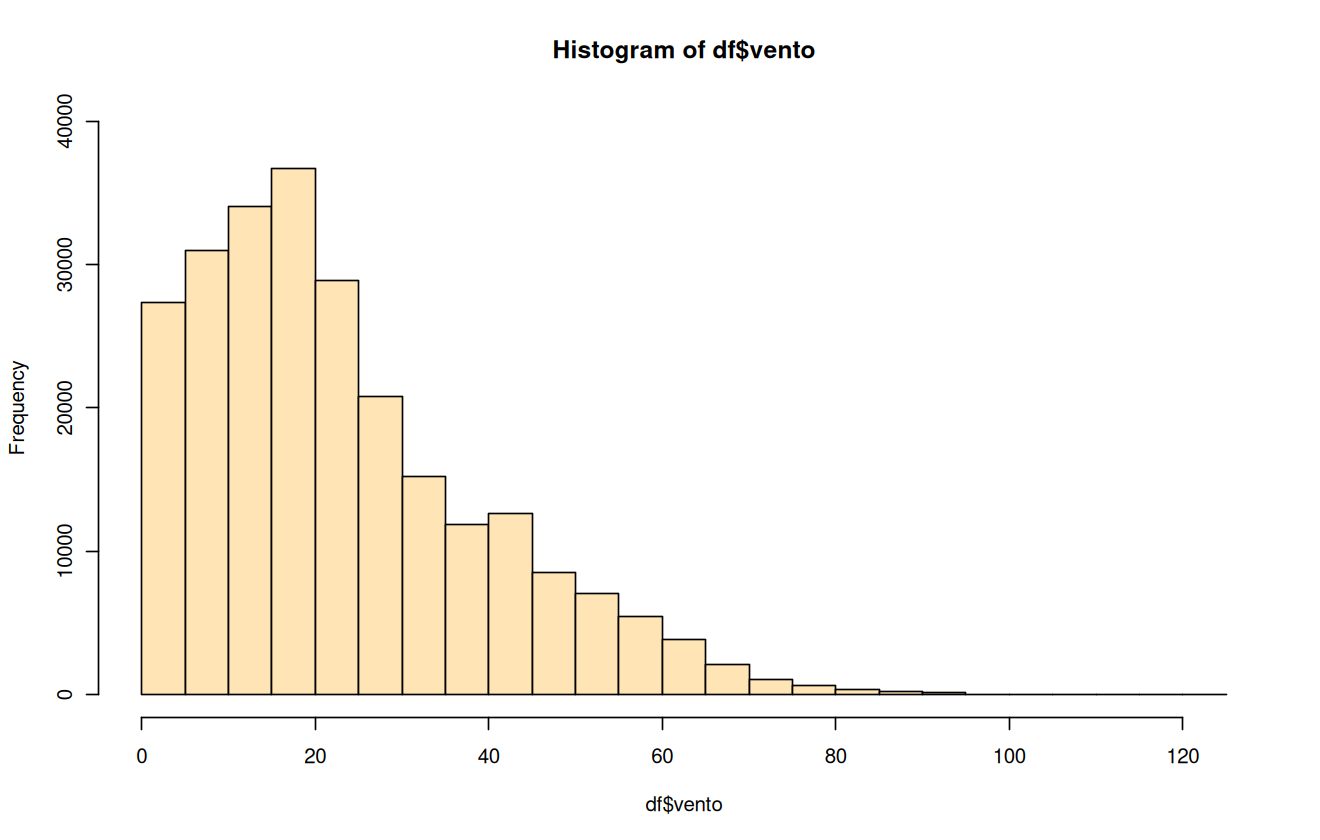

In [227]:
dimgraf(11,7)
hist(df$vento, col="moccasin", ylim=c(0,40000))

In [228]:
# quais registros com vento acima de 100 km/h?
df[df$vento > 100,]

,horario,temp,vento,umid,sensacao
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
121085,2019-04-28 18:20:00,20.9,107.2,81.4,19.7
134873,2019-08-02 20:00:00,19.1,100.1,78.3,17.8
136575,2019-08-14 15:40:00,17.1,100.1,66.8,15.5
136576,2019-08-14 15:50:00,17.1,100.1,66.8,15.5
136577,2019-08-14 16:00:00,17.1,100.1,66.8,15.5
136578,2019-08-14 16:10:00,17.1,100.1,66.8,15.5
136579,2019-08-14 16:20:00,17.1,100.1,66.8,15.5
139745,2019-09-05 16:30:00,18.3,100.1,72.3,16.8
139746,2019-09-05 16:40:00,18.3,100.1,72.3,16.8


Todos os dias foram em 2019. O que teria acontecido entre abril e outubro de 2019?   
Pesquisar o que houve nesses dias, pois ventos de mais de 100 km/h causam grande destruição e, a partir 118 km/h já é considerado furacão.   
A propósito, nunca houve furacão em Campinas...

### Umidade do ar

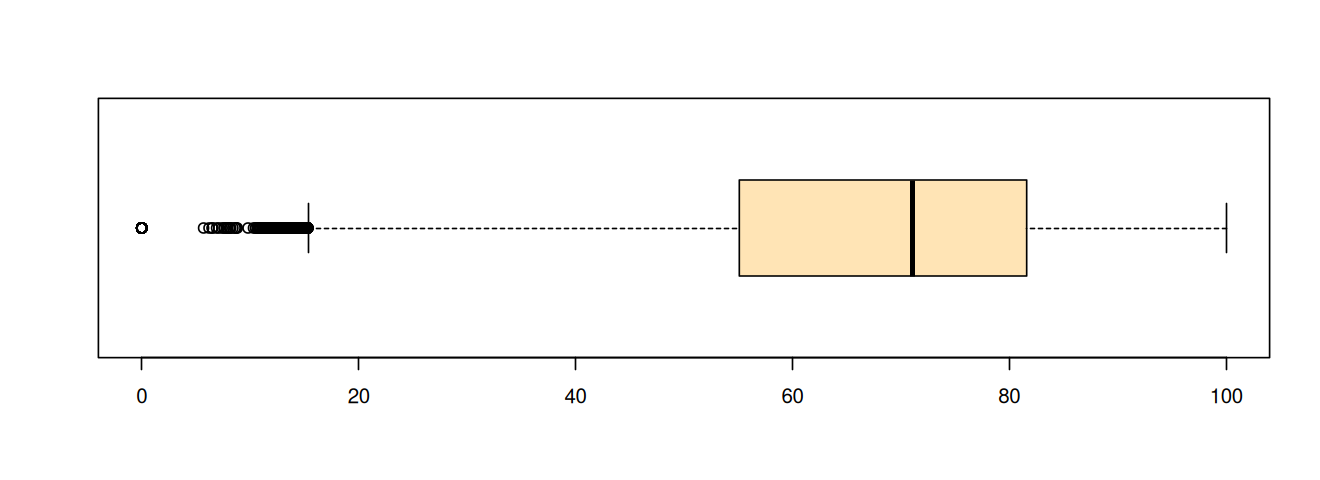

In [229]:
dimgraf(11,4)
boxplot(df$umid, horizontal=TRUE, col="moccasin")

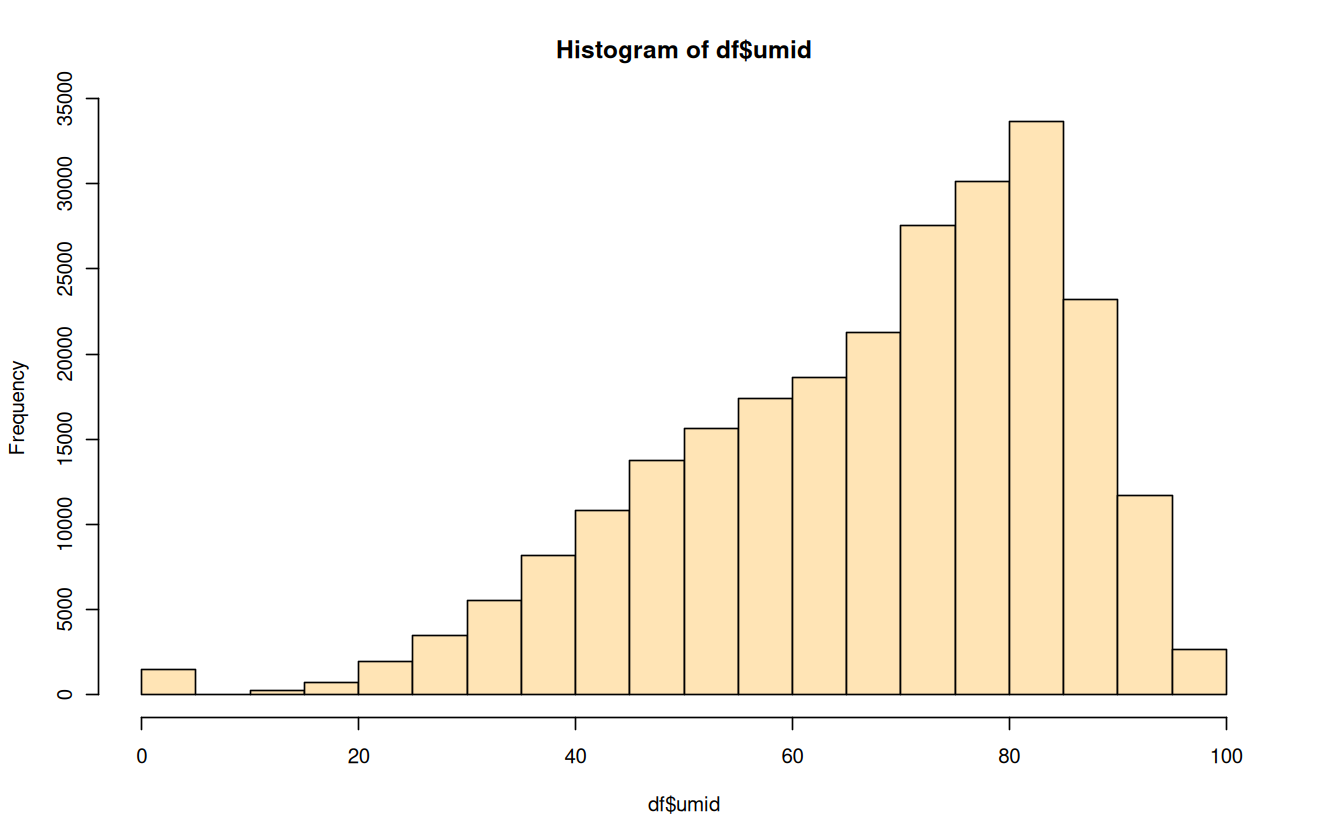

In [230]:
dimgraf(11,7)
hist(df$umid, col="moccasin")

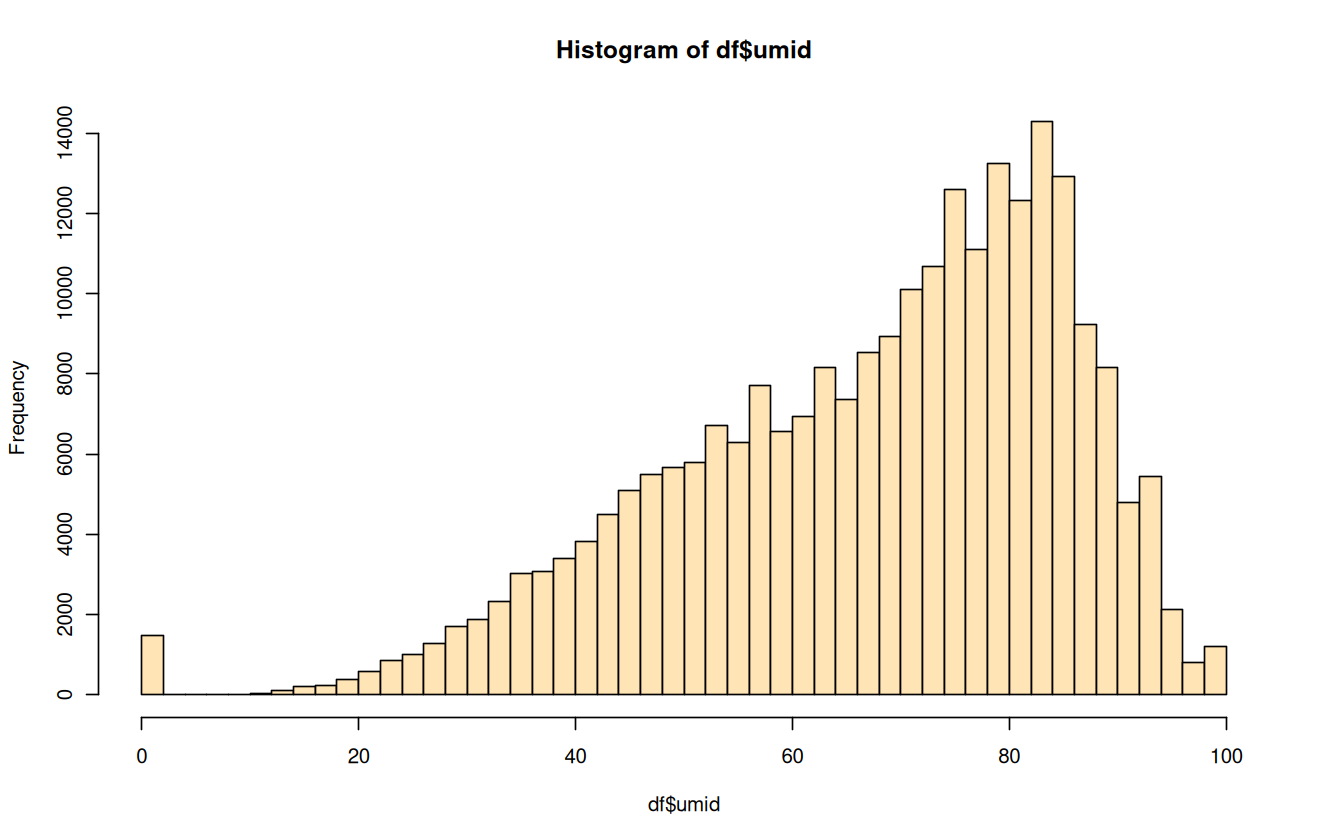

In [231]:
hist(df$umid, breaks=60, col="moccasin")

Tem uma grande quantidade de registros (aparentemente uns 1700) registrando 0% de umidade.   
É um problema, com certeza, pois _desertos_ tem em torno de 10% de umidade...

In [232]:
head(df[df$umid == 0, ])

,horario,temp,vento,umid,sensacao
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
104918,2019-01-05 07:00:00,20.6,17.0,0,19.4
104919,2019-01-05 07:10:00,20.6,15.7,0,19.5
104920,2019-01-05 07:20:00,20.6,15.7,0,19.5
104921,2019-01-05 07:30:00,20.7,14.7,0,19.6
104922,2019-01-05 07:40:00,20.8,15.2,0,19.6
104923,2019-01-05 07:50:00,20.8,15.2,0,19.6


Pois é, 2019 **e** 2020. 

Como se comportaram as medidas abaixo de 20% de umidade?

há 2386 registros abaixo de 20% de umidade

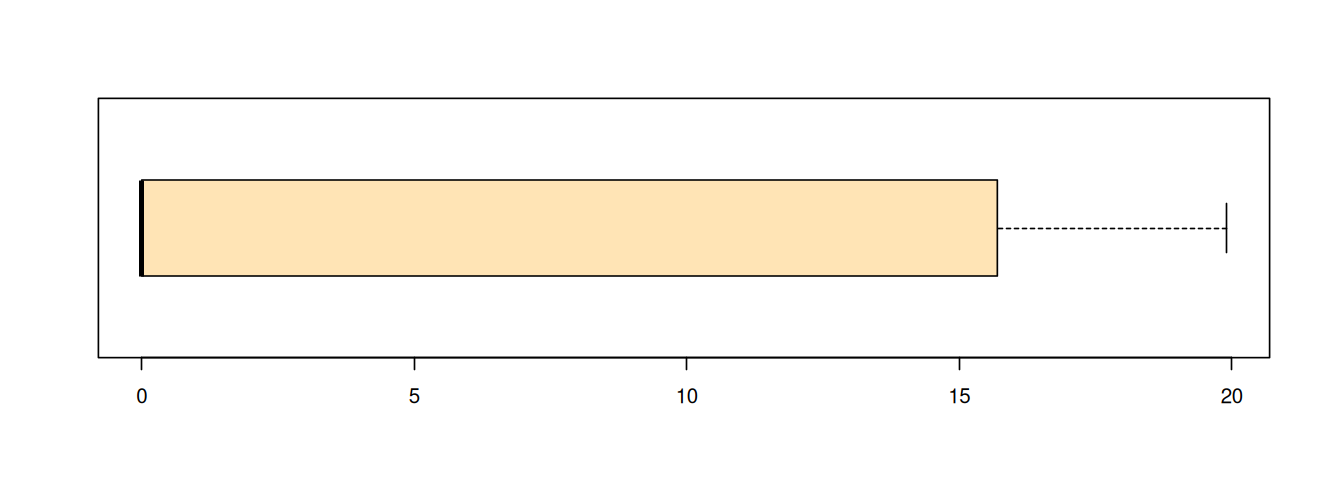

In [233]:
cat("há",length(df$umid[df$umid < 20]),"registros abaixo de 20% de umidade")
dimgraf(11,4)
boxplot(df$umid[df$umid < 20], horizontal=TRUE, col="moccasin")

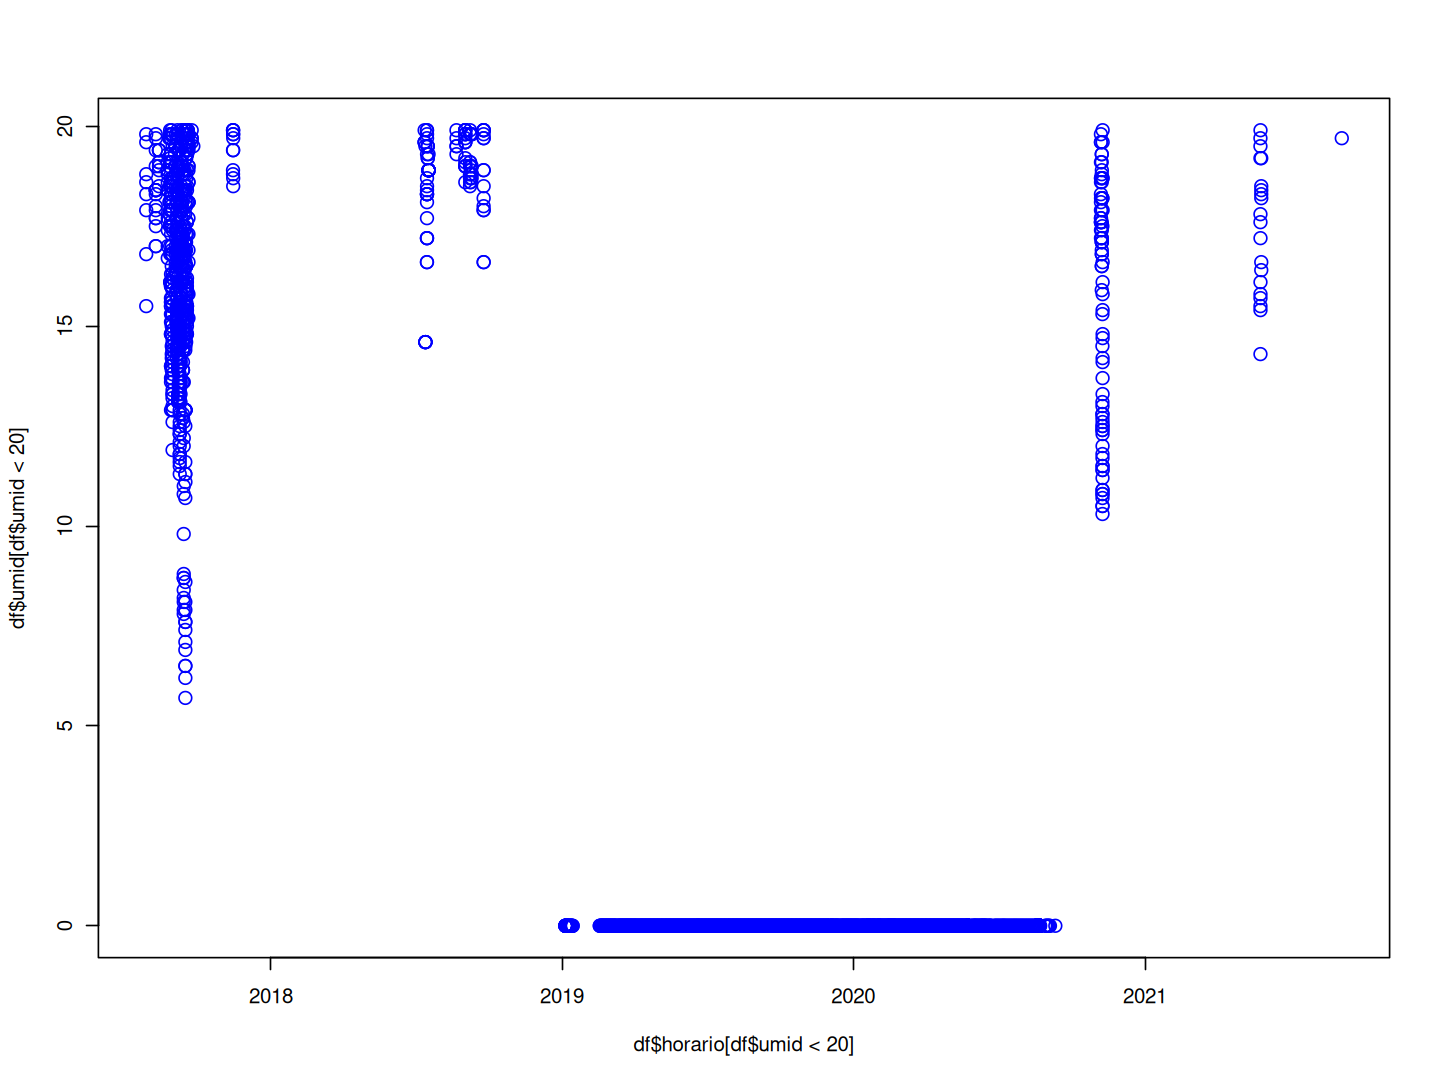

In [237]:
dimgraf(12,9)
plot(df$horario[df$umid < 20], df$umid[df$umid < 20],cex=1.3, col="blue")

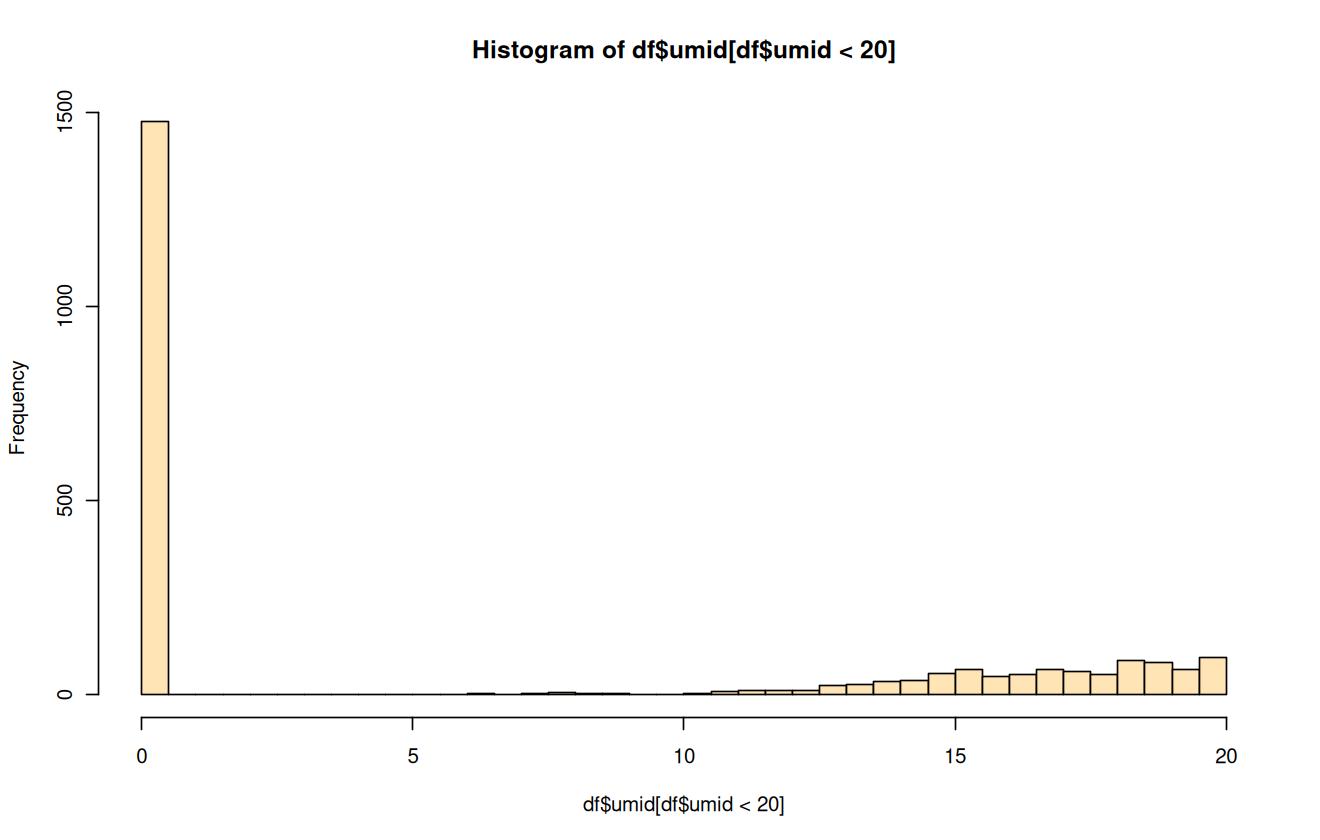

In [238]:
dimgraf(11,7)
hist(df$umid[df$umid < 20], breaks=30, col="moccasin")

Registros em torno de 10% são ruins, aparentemente são raros e devem ser estudados.   
Observações com 0% são seguramente erros e convém que sejam eliminados.

Como se comportam as outras variáveis (ou _features_) para as observações em que a umidade é zero?

In [239]:
linhas <- df$umid == 0.0
cat("Há",sum(linhas),"com umidade zero")

Há 1476 com umidade zero

In [240]:
df_umid0 <- df[linhas,]
head(df_umid0)
tail(df_umid0)

,horario,temp,vento,umid,sensacao
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
104918,2019-01-05 07:00:00,20.6,17.0,0,19.4
104919,2019-01-05 07:10:00,20.6,15.7,0,19.5
104920,2019-01-05 07:20:00,20.6,15.7,0,19.5
104921,2019-01-05 07:30:00,20.7,14.7,0,19.6
104922,2019-01-05 07:40:00,20.8,15.2,0,19.6
104923,2019-01-05 07:50:00,20.8,15.2,0,19.6


,horario,temp,vento,umid,sensacao
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
190388,2020-08-30 16:50:00,21.5,47.8,0,20.2
190532,2020-08-31 16:50:00,21.5,47.8,0,20.2
190674,2020-09-01 16:50:00,21.5,47.8,0,20.2
190818,2020-09-02 16:50:00,21.5,47.8,0,20.2
190962,2020-09-03 16:50:00,21.5,47.8,0,20.2
191935,2020-09-10 11:00:00,24.7,37.0,0,23.5


In [241]:
summary(df_umid0)

    horario                            temp           vento            umid  
 Min.   :2019-01-05 07:00:00.00   Min.   : 6.20   Min.   : 0.00   Min.   :0  
 1st Qu.:2019-08-01 07:07:30.00   1st Qu.:17.00   1st Qu.:15.60   1st Qu.:0  
 Median :2020-01-19 22:05:00.00   Median :20.20   Median :23.85   Median :0  
 Mean   :2019-12-15 02:27:48.28   Mean   :19.82   Mean   :27.43   Mean   :0  
 3rd Qu.:2020-04-18 13:07:30.00   3rd Qu.:22.00   3rd Qu.:36.10   3rd Qu.:0  
 Max.   :2020-09-10 11:00:00.00   Max.   :32.30   Max.   :81.80   Max.   :0  
    sensacao    
 Min.   : 2.10  
 1st Qu.:15.50  
 Median :19.00  
 Mean   :18.39  
 3rd Qu.:20.90  
 Max.   :30.40  

São basicamente 2019 e 2020.

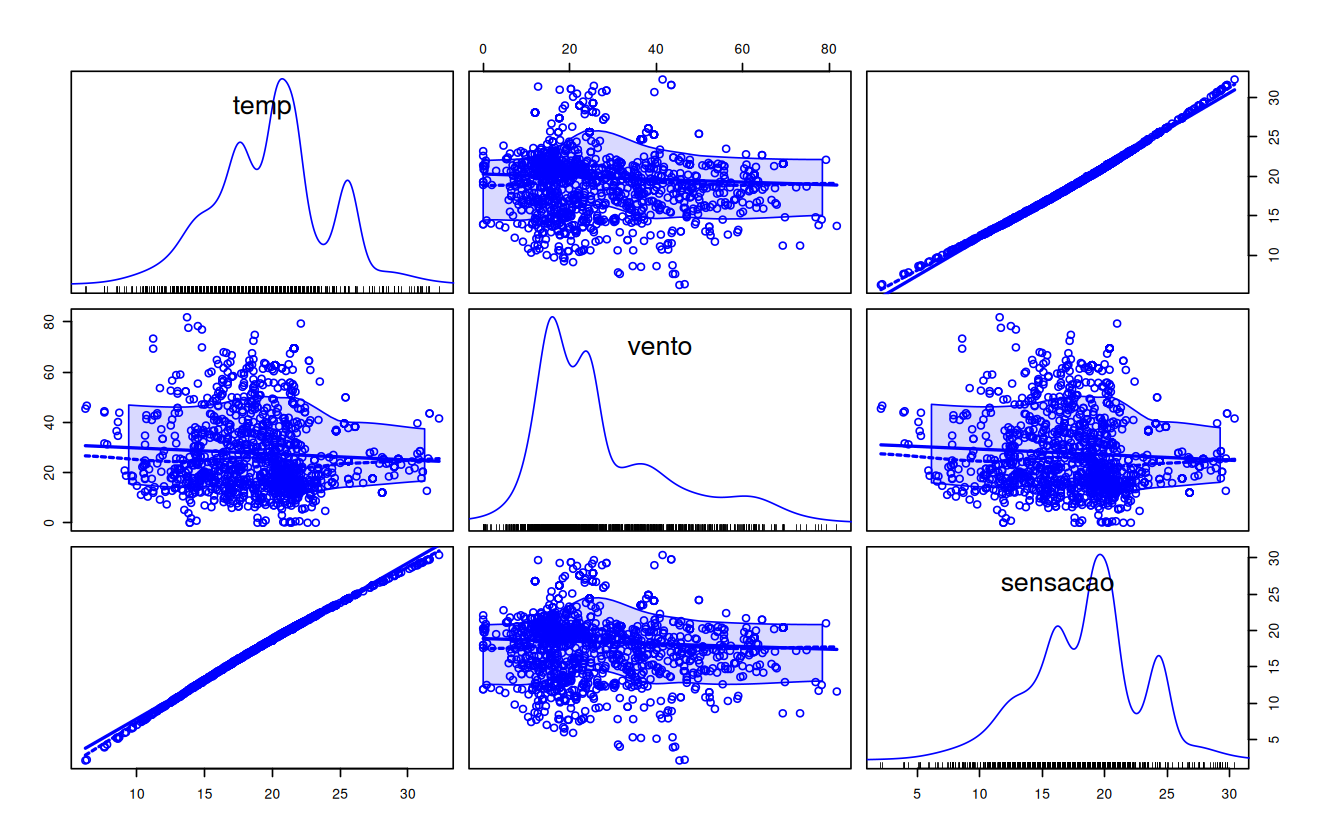

In [242]:
library(car)
scatterplotMatrix(df_umid0[,c("temp", "vento", "sensacao")])

Os valores superficialmente não parecem apresentar problemas, apenas a umidade. Assim, o mais indicado seria perder apenas os dados da umidade para essas observações.

In [243]:
df$umid[df$umid < 5] <- NA

In [244]:
summary(df)

    horario                            temp           vento       
 Min.   :2017-01-01 00:00:00.00   Min.   : 4.60   Min.   :  0.00  
 1st Qu.:2018-03-20 21:27:30.00   1st Qu.:18.90   1st Qu.: 10.70  
 Median :2019-05-29 00:45:00.00   Median :21.70   Median : 19.30  
 Mean   :2019-07-21 01:54:23.86   Mean   :22.22   Mean   : 23.01  
 3rd Qu.:2020-12-28 11:32:30.00   3rd Qu.:25.80   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00.00   Max.   :37.40   Max.   :120.10  
                                                                  
      umid           sensacao    
 Min.   :  5.70   Min.   :-0.20  
 1st Qu.: 55.50   1st Qu.:17.50  
 Median : 71.10   Median :20.50  
 Mean   : 67.69   Mean   :20.84  
 3rd Qu.: 81.60   3rd Qu.:24.60  
 Max.   :100.00   Max.   :99.90  
 NA's   :1476                    

### Sensação térmica

Algo estranho nos valores da sensação térmica (`sensacao`)?   
Quantas vezes você ouviu "Está quente! A sensação térmica de hoje é 100°C" ...

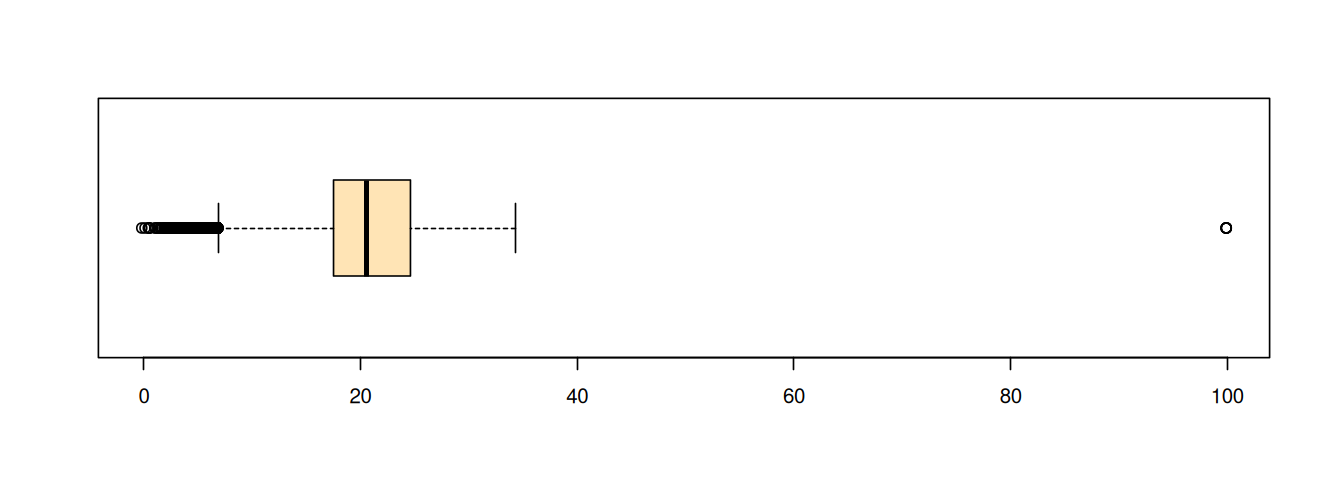

In [245]:
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$sensacao, horizontal=TRUE, col="moccasin")

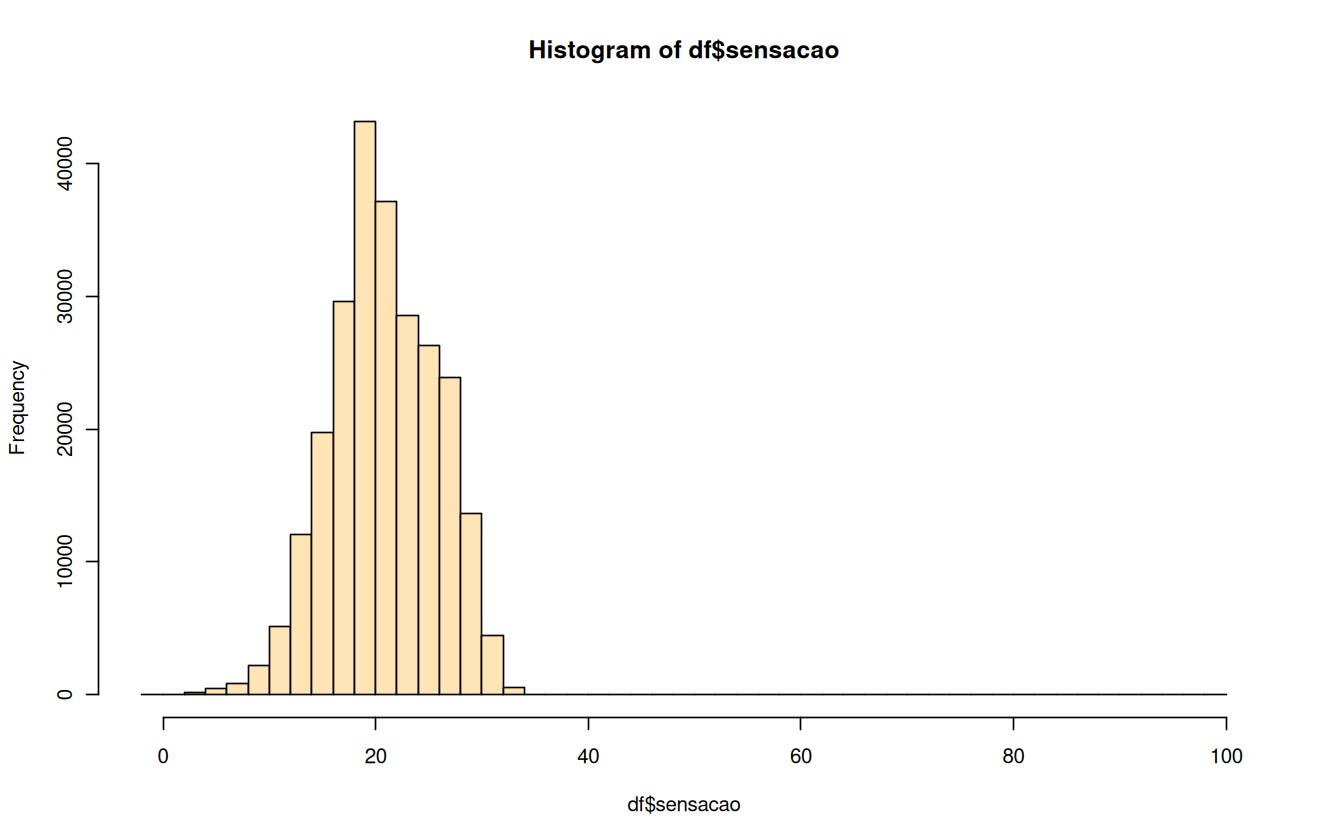

In [246]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$sensacao, breaks=50, col="moccasin")

A distribuição dos valores, diferentemente do caso da umidade, não são contínuos até 100°C. Aparentemente os casos com 100°C são isolados.

In [247]:
df[df$sensacao > 40,]

,horario,temp,vento,umid,sensacao
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
87668,2018-09-07 07:10:00,13.4,37.0,75.3,99.9
87812,2018-09-08 07:10:00,16.1,26.3,64.5,99.9
87956,2018-09-09 07:10:00,15.1,28.1,75.8,99.9
88100,2018-09-10 07:10:00,14.8,33.4,74.5,99.9
88244,2018-09-11 07:10:00,15.4,34.7,76.2,99.9


Interessante. Há cinco registros com sensação térmica de 99,9°C: são as medidas das 7h10 de 7 a 11 de setembro de 2018. Cinco dias em seguida, no mesmo horário, sendo o primeiro um feriado...

Como estão as medidas _vizinhas_?

In [248]:
# quais índices das linhas com problemas?
linhas <- which(df$sensacao == 99.9)
linhas

[1] 86401 86545 86689 86833 86977

In [249]:
for (x in linhas) {
    medidas <- df[(x-3):(x+3), "sensacao"] # desde três valores antes até três depois
    print(medidas)                         # descarte o valor incorreto para calcular a média
    media   <- mean(medidas[-4])
    print(media)
}

[1] 10.3 10.6 10.6 99.9 11.7 12.1 12.4
[1] 11.28333
[1] 13.4 13.7 13.9 99.9 14.9 15.5 16.1
[1] 14.58333
[1] 12.7 12.8 13.0 99.9 13.4 13.6 13.9
[1] 13.23333
[1] 12.0 12.3 12.5 99.9 13.2 13.6 14.1
[1] 12.95
[1] 12.9 13.0 13.3 99.9 14.0 14.4 14.8
[1] 13.73333


Aparentemente ocorreu um erro de medição _precisamente_ às 7h10 desses dias. As medidas tomadas antes e depois do horário estão boas. Uma saída seria descartar o valor problemático substituindo-o pela média dos seus vizinhos.

In [250]:
for (x in linhas) {
    medidas <- df[(x-3):(x+3), "sensacao"]  # 
    media   <- mean(medidas[-4])
    df[x, "sensacao"] <- media
}

In [251]:
df[linhas,]

,horario,temp,vento,umid,sensacao
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
87668,2018-09-07 07:10:00,13.4,37.0,75.3,11.28333
87812,2018-09-08 07:10:00,16.1,26.3,64.5,14.58333
87956,2018-09-09 07:10:00,15.1,28.1,75.8,13.23333
88100,2018-09-10 07:10:00,14.8,33.4,74.5,12.95000
88244,2018-09-11 07:10:00,15.4,34.7,76.2,13.73333


In [252]:
summary(df)

    horario                            temp           vento       
 Min.   :2017-01-01 00:00:00.00   Min.   : 4.60   Min.   :  0.00  
 1st Qu.:2018-03-20 21:27:30.00   1st Qu.:18.90   1st Qu.: 10.70  
 Median :2019-05-29 00:45:00.00   Median :21.70   Median : 19.30  
 Mean   :2019-07-21 01:54:23.86   Mean   :22.22   Mean   : 23.01  
 3rd Qu.:2020-12-28 11:32:30.00   3rd Qu.:25.80   3rd Qu.: 32.20  
 Max.   :2022-06-07 09:30:00.00   Max.   :37.40   Max.   :120.10  
                                                                  
      umid           sensacao    
 Min.   :  5.70   Min.   :-0.20  
 1st Qu.: 55.50   1st Qu.:17.50  
 Median : 71.10   Median :20.50  
 Mean   : 67.69   Mean   :20.83  
 3rd Qu.: 81.60   3rd Qu.:24.60  
 Max.   :100.00   Max.   :34.30  
 NA's   :1476                    

Agora está pronto para ser salvo para análise.
É interessante manter um banco de dados de cada etapa para compartimentalizar o processo: se houver algum problema em um passo posterior, basta voltar um passo, corrigir/atualizar o _dataset_ e refazer o passo.

In [253]:
cepagri_01 <- df

In [254]:
save(cepagri_01, file="cepagri_01_variaveis.RData")

## Carga